In [22]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
import os
import random
import timm
import torch
import torchvision
import torch.nn as nn

In [23]:
torcg = torch.cuda.is_available()
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

nvidia_smi = os.popen('nvidia-smi').read()
print(nvidia_smi)


Wed Mar 19 03:12:42 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 561.09                 Driver Version: 561.09         CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3060 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   47C    P8             13W /   95W |    1303MiB /   6144MiB |     11%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [24]:
# Is there any Python lib which can read the zip file and extract the files in it?
# Yes, the zipfile module in Python can be used to read and extract files from a zip archive.
import zipfile
import os
import shutil

# Function to extract zip file
def extract_zip(zip_path, extract_to=None):
    """
    Extract a zip file to the specified directory
    
    Args:
        zip_path (str): Path to the zip file
        extract_to (str, optional): Path to extract the files to. If None, extracts to the same directory
    
    Returns:
        str: Path to the extracted directory
    """
    if extract_to is None:
        extract_to = os.path.dirname(zip_path)
    
    # Create the extraction directory if it doesn't exist
    os.makedirs(extract_to, exist_ok=True)
    
    # Extract the zip file
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_to)
    
    print(f"Extracted {zip_path} to {extract_to}")
    return extract_to

# Example usage
zip_path = r"C:\Users\zeshanm\Desktop\ViT---Solar-PV-Anamoly-Detection\data\2020-02-14_InfraredSolarModules.zip"
extract_dir = r"C:\Users\zeshanm\Desktop\ViT---Solar-PV-Anamoly-Detection\data\2020-02-14_InfraredSolarModules"
extracted_path = extract_zip(zip_path, extract_dir)

Extracted C:\Users\zeshanm\Desktop\ViT---Solar-PV-Anamoly-Detection\data\2020-02-14_InfraredSolarModules.zip to C:\Users\zeshanm\Desktop\ViT---Solar-PV-Anamoly-Detection\data\2020-02-14_InfraredSolarModules


In [25]:
import pandas as pd
import json

# Function to read JSON file and convert it to a DataFrame (Are you creating a new function?)
def read_json_to_dataframe(json_path):
    """
    Read a JSON file and convert it to a pandas DataFrame
    
    Args:
        json_path (str): Path to the JSON file
    
    Returns:
        pd.DataFrame: DataFrame containing the JSON data
    """
    with open(json_path, 'r') as f:
        data = json.load(f)
    
    df = pd.json_normalize(data)
    return df

json_path = r"C:\Users\zeshanm\Desktop\ViT---Solar-PV-Anamoly-Detection\data\2020-02-14_InfraredSolarModules\InfraredSolarModules\module_metadata.json"
df = read_json_to_dataframe(json_path)
print(df)



%pip install scikit-learn
                           

  13357.image_filepath 13357.anomaly_class 13356.image_filepath  \
0     images/13357.jpg          No-Anomaly     images/13356.jpg   

  13356.anomaly_class 19719.image_filepath 19719.anomaly_class  \
0          No-Anomaly     images/19719.jpg          No-Anomaly   

  11542.image_filepath 11542.anomaly_class 11543.image_filepath  \
0     images/11542.jpg          No-Anomaly     images/11543.jpg   

  11543.anomaly_class  ... 8488.image_filepath 8488.anomaly_class  \
0          No-Anomaly  ...     images/8488.jpg         Vegetation   

  8489.image_filepath 8489.anomaly_class 7464.image_filepath  \
0     images/8489.jpg         Vegetation     images/7464.jpg   

  7464.anomaly_class 18065.image_filepath 18065.anomaly_class  \
0           Cracking     images/18065.jpg          No-Anomaly   

  13354.image_filepath 13354.anomaly_class  
0     images/13354.jpg          No-Anomaly  

[1 rows x 40000 columns]
Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.
Processing sample image: C:\Users\zeshanm\Desktop\ViT---Solar-PV-Anamoly-Detection\data\2020-02-14_InfraredSolarModules\InfraredSolarModules\images/13357.jpg


C:\Users\zeshanm\AppData\Local\Temp\ipykernel_19040\707429176.py:146: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sample_path = os.path.join(extract_dir, 'InfraredSolarModules', df.iloc[0][0])


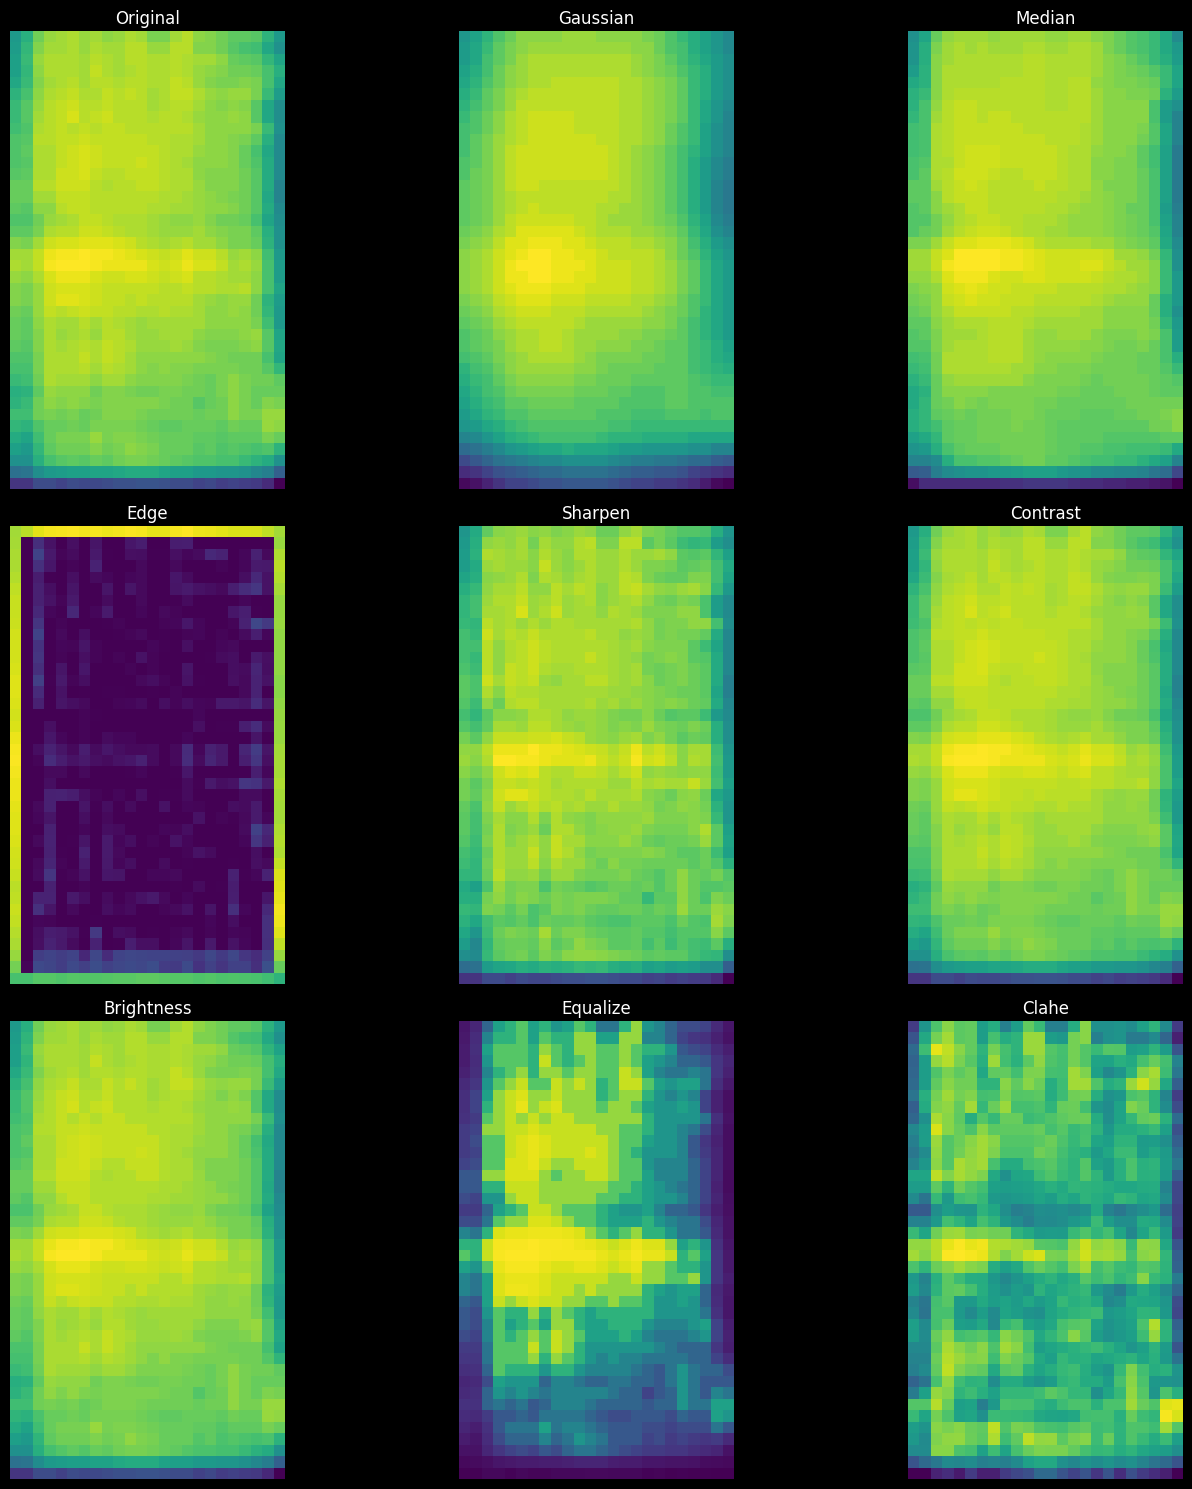

In [ ]:
import os
import numpy as np

np.random.seed(42)  # For reproducibility
from PIL import Image, ImageFilter, ImageEnhance
import cv2
%pip install -q scikit-image
from skimage import filters, exposure
import torch

import matplotlib.pyplot as plt
import torchvision.transforms as transforms

# Function to load an image from file path
def load_image(image_path):
    """
    Load an image from file path
    
    Args:
        image_path (str): Path to the image file
    
    Returns:
        PIL.Image: Loaded image
    """
    return Image.open(image_path)

# Function to apply various filters to an image
def apply_filters(image, filter_type='gaussian', **kwargs):
    """
    Apply various filters to an image
    
    Args:
        image (PIL.Image): Input image
        filter_type (str): Type of filter to apply. Options: 'gaussian', 'median', 'edge', 
                           'sharpen', 'contrast', 'brightness', 'equalize', 'clahe'
        **kwargs: Additional parameters for specific filters
    
    Returns:
        PIL.Image or numpy.ndarray: Filtered image
    """
    if filter_type == 'gaussian':
        radius = kwargs.get('radius', 2)
        return image.filter(ImageFilter.GaussianBlur(radius))
    
    elif filter_type == 'median':
        size = kwargs.get('size', 3)
        return image.filter(ImageFilter.MedianFilter(size))
    
    elif filter_type == 'edge':
        return image.filter(ImageFilter.FIND_EDGES)
    
    elif filter_type == 'sharpen':
        return image.filter(ImageFilter.SHARPEN)
    
    elif filter_type == 'contrast':
        factor = kwargs.get('factor', 1.5)
        enhancer = ImageEnhance.Contrast(image)
        return enhancer.enhance(factor)
    
    elif filter_type == 'brightness':
        factor = kwargs.get('factor', 1.2)
        enhancer = ImageEnhance.Brightness(image)
        return enhancer.enhance(factor)
    
    elif filter_type == 'equalize':
        # Convert to numpy array for histogram equalization
        img_np = np.array(image)
        # Check if the image is grayscale or color
        if len(img_np.shape) == 2 or img_np.shape[2] == 1:
            img_eq = exposure.equalize_hist(img_np)
        else:
            # Apply equalization to each channel
            img_eq = np.zeros_like(img_np, dtype=np.float64)
            for i in range(img_np.shape[2]):
                img_eq[:, :, i] = exposure.equalize_hist(img_np[:, :, i])
        
        # Convert back to uint8 for PIL
        img_eq = (img_eq * 255).astype(np.uint8)
        return Image.fromarray(img_eq)
    
    elif filter_type == 'clahe':
        # CLAHE (Contrast Limited Adaptive Histogram Equalization)
        clip_limit = kwargs.get('clip_limit', 2.0)
        tile_grid_size = kwargs.get('tile_grid_size', (8, 8))
        
        img_np = np.array(image)
        
        # Convert to LAB color space if the image is color
        if len(img_np.shape) == 3 and img_np.shape[2] == 3:
            img_lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
            l, a, b = cv2.split(img_lab)
            
            clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
            cl = clahe.apply(l)
            
            # Merge the CLAHE enhanced L-channel back with A and B channels
            img_clahe = cv2.merge((cl, a, b))
            img_clahe = cv2.cvtColor(img_clahe, cv2.COLOR_LAB2RGB)
        else:
            # For grayscale image
            clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
            img_clahe = clahe.apply(img_np)
            
        return Image.fromarray(img_clahe)
    
    else:
        raise ValueError(f"Unsupported filter type: {filter_type}")

# Function to visualize the effect of different filters
def visualize_filters(image_path):
    """
    Load an image and visualize the effect of different filters
    
    Args:
        image_path (str): Path to the image file
    """
    image = load_image(image_path)
    
    # Define filter types to apply
    filter_types = ['gaussian', 'median', 'edge', 'sharpen', 
                   'contrast', 'brightness', 'equalize', 'clahe']
    
    # Create subplots
    fig, axes = plt.subplots(3, 3, figsize=(15, 15))
    
    # Original image
    axes[0, 0].imshow(image)
    axes[0, 0].set_title('Original')
    axes[0, 0].axis('off')
    
    # Apply and display different filters
    for i, filter_type in enumerate(filter_types, 1):
        row, col = i // 3, i % 3
        filtered_img = apply_filters(image, filter_type)
        axes[row, col].imshow(filtered_img)
        axes[row, col].set_title(filter_type.capitalize())
        axes[row, col].axis('off')
    
    plt.tight_layout()
    plt.show()

# Example usage with a sample image path from the dataset
def process_sample_image():
    """
    Process a sample image from the dataset and show the filtered versions
    """
    # Get a sample image path from the DataFrame
    sample_path = os.path.join(extract_dir, 'InfraredSolarModules', df.iloc[0][0])
    
    # Ensure the path exists
    if os.path.exists(sample_path):
        print(f"Processing sample image: {sample_path}")
        visualize_filters(sample_path)
    else:
        print(f"File not found: {sample_path}")
        # Try to find any image in the directory
        base_dir = os.path.join(extract_dir, 'InfraredSolarModules')
        for root, dirs, files in os.walk(base_dir):
            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    sample_path = os.path.join(root, file)
                    print(f"Using alternative image: {sample_path}")
                    visualize_filters(sample_path)
                    return

# Call the function to process a sample image
process_sample_image()

In [ ]:
# How can I split the dataset on the basis of classes defined in the metadata?
# To split the dataset based on classes defined in the metadata, you can follow these steps:    
# 1. Load the metadata JSON file into a DataFrame.
# 2. Extract the class labels from the DataFrame.
# 3. Create a directory structure for the split dataset.
# 4. Move or copy the images into their respective class directories
# 5. Optionally, create a train-test split for each class.
# 6. Save the split dataset paths for later use.
import os
import shutil
import pandas as pd
import json
import random
import numpy as np
import cv2


# Function to split dataset based on classes defined in metadata
def split_dataset_by_classes(metadata_path, image_dir, output_dir, test_size=0.2):
    """
    Split dataset based on classes defined in metadata
    
    Args:
        metadata_path (str): Path to the metadata JSON file
        image_dir (str): Directory containing the images
        output_dir (str): Directory to save the split dataset
        test_size (float): Proportion of the dataset to include in the test split
    
    Returns:
        None
    """
    # Load metadata JSON file into a DataFrame
    with open(metadata_path, 'r') as f:
        metadata = json.load(f)
    
    df = pd.json_normalize(metadata)
    
    # Extract class labels from the DataFrame
    class_labels = df['class'].unique()
    
    # Create output directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)
    
    # Create directories for each class
    for label in class_labels:
        os.makedirs(os.path.join(output_dir, 'train', label), exist_ok=True)
        os.makedirs(os.path.join(output_dir, 'test', label), exist_ok=True)
    
    # Split images into train and test sets based on classes
    for label in class_labels:
        # Get all images for the current class
        class_images = df[df['class'] == label]['image_path'].tolist()
        
        # Shuffle and split the images into train and test sets
        random.shuffle(class_images)
        split_index = int(len(class_images) * (1 - test_size))
        train_images = class_images[:split_index]
        test_images = class_images[split_index:]
        
        # Move or copy images to their respective directories
        for img_path in train_images:
            shutil.copy(os.path.join(image_dir, img_path), os.path.join(output_dir, 'train', label))
        
        for img_path in test_images:
            shutil.copy(os.path.join(image_dir, img_path), os.path.join(output_dir, 'test', label))
            print(f"Copied {img_path} to {os.path.join(output_dir, 'test', label)}")
            


In [27]:
# Set random seed for reproducibility
torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

# Define a simple CNN model
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.fc1 = nn.Linear(32 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, num_classes)
        
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 8 * 8)  # Assuming input image is 32x32
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Create an instance of the model
model = SimpleCNN()
print(model)

# Define a Vision Transformer model using timm

class ViTModel(nn.Module):
    def __init__(self, num_classes=10):
        super(ViTModel, self).__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=num_classes)

    def forward(self, x):
        return self.vit(x)
    
# Create an instance of the ViT model
vit_model = ViTModel()
print(vit_model)


SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
ViTModel(
  (vit): VisionTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      (norm): Identity()
    )
    (pos_drop): Dropout(p=0.0, inplace=False)
    (patch_drop): Identity()
    (norm_pre): Identity()
    (blocks): Sequential(
      (0): Block(
        (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=768, out_features=2304, bias=True)
          (q_norm): Identity()
          (k_norm): Identity()
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in

In [28]:
# How can I see the Convolutional layers of the model?
# Print the model architecture

print("Convolutional layers of the model:")
print(model.conv1)
print(model.conv2)


# Can I also see the SNE View of the Convolutional layers?
# Visualize the model architecture using torchviz
from torchviz import make_dot
from torch.autograd import Variable



# How can I see the SNE View of the Convolutional layers?
# Visualize the model architecture using torchviz
from torchviz import make_dot
from torch.autograd import Variable
import torch
import torch.nn as nn



# Create a dummy input tensor with the same shape as the model's input
dummy_input = Variable(torch.randn(1, 3, 32, 32))  # Batch size of 1, 3 channels, 32x32 image

# Forward pass through the model to get the output
output = model(dummy_input)
# Visualize the model architecture using torchviz
dot = make_dot(output, params=dict(list(model.named_parameters())))
dot.format = 'png'
dot.render('model_architecture')

# Display the generated SNE view
from PIL import Image


# Q: What is tSNE and how does it work?
# t-SNE (t-distributed Stochastic Neighbor Embedding) is a machine learning algorithm for dimensionality reduction that is particularly well-suited for visualizing high-dimensional datasets. It works by converting similarities between data points into joint probabilities and then minimizing the divergence between these probabilities in a lower-dimensional space. The key steps are:
# 1. Compute pairwise similarities in the high-dimensional space.
# 2. Convert these similarities into probabilities using a Gaussian distribution.
# 3. Initialize points in the lower-dimensional space randomly.
# 4. Compute pairwise similarities in the lower-dimensional space using a t-distribution.
# 5. Minimize the Kullback-Leibler divergence between the two distributions using gradient descent.
# 6. The result is a lower-dimensional representation that preserves local structure and relationships between data points.
# 7. t-SNE is often used for visualizing clusters or patterns in data, especially in fields like computer vision and natural language processing.
# 8. It is particularly effective for visualizing high-dimensional data in a two or three-dimensional space.
# 9. However, it can be computationally expensive for large datasets and may not preserve global structure well.
# 10. t-SNE is widely used in exploratory data analysis and visualization tasks.


# So TSNE Can be also applied to the Convolutional layers of the model?
# Yes, t-SNE can be applied to the feature maps or activations of the convolutional layers of a model. By extracting the feature maps from the convolutional layers during a forward pass and then applying t-SNE, you can visualize the high-dimensional representations learned by the model. This can help you understand how the model is clustering or separating different classes in the feature space.
# It can also provide insights into the model's performance and the quality of the learned features. However, keep in mind that t-SNE is primarily a visualization tool and may not always reflect the true structure of the data in lower dimensions.
# It is important to interpret the results carefully and consider other evaluation metrics as well.
# To apply t-SNE to the feature maps of the convolutional layers, you can follow these steps:
# 1. Forward pass through the model to obtain feature maps from the convolutional layers.
# 2. Flatten the feature maps to create a high-dimensional representation.
# 3. Apply t-SNE to the flattened feature maps to reduce the dimensionality.
# 4. Visualize the results using scatter plots or other visualization techniques.
# 5. Optionally, color the points based on their class labels to see how well the model separates different classes.
# 6. Interpret the results to gain insights into the model's performance and learned features.
# 7. Consider using other dimensionality reduction techniques (e.g., PCA) for comparison.
# 8. Experiment with different t-SNE parameters (e.g., perplexity) to see how they affect the visualization.
# 9. Save the t-SNE visualization for future reference or analysis.
# 10. Use the t-SNE results to guide further model improvements or feature engineering.
# 11. Document the findings and share them with your team or community for feedback.
# 12. Consider using t-SNE as part of a larger analysis pipeline to understand the model's behavior and performance.
# 13. Explore other visualization techniques (e.g., UMAP) for comparison and complementary insights.
# 14. Use the t-SNE results to inform hyperparameter tuning or model architecture changes.
# 15. Continuously iterate on the model and visualization process to improve understanding and performance.
# 16. Share the t-SNE visualizations with stakeholders to communicate the model's performance and behavior.
# 17. Use the t-SNE results to identify potential areas for improvement in the model or data preprocessing.
# 18. Consider using t-SNE in combination with other evaluation metrics to get a comprehensive view of the model's performance.
# 19. Explore the t-SNE results in the context of the specific problem domain to gain deeper insights.


# 20. Use the t-SNE visualizations to guide feature selection or engineering efforts.
# 21. Experiment with different t-SNE implementations or libraries for potential performance improvements.
# 22. Consider using t-SNE in conjunction with other unsupervised learning techniques for a more comprehensive analysis.
# 23. Use the t-SNE results to inform data augmentation strategies or other preprocessing techniques.
# 24. Explore the t-SNE visualizations in the context of different model architectures or training strategies.
# 25. Use the t-SNE results to identify potential biases or imbalances in the dataset.
# 26. Consider using t-SNE as part of a larger model interpretability framework to understand the model's decisions.
# 27. Use the t-SNE visualizations to communicate findings to non-technical stakeholders or team members.
# 28. Explore the t-SNE results in the context of different evaluation metrics or performance benchmarks.
# 29. Use the t-SNE results to guide model selection or ensemble strategies.

# Q: How can I apply tSNE to the Convolutional layers of the model?
# To apply t-SNE to the convolutional layers of the model, you can follow these steps:


# Feature Map of IR Images is a High Dimensional Data?
# Yes, the feature map of infrared (IR) images is considered high-dimensional data. Feature maps are typically generated by convolutional layers in a neural network, and they represent the learned features of the input data. The dimensionality of these feature maps can be quite large, especially when dealing with deep convolutional neural networks (CNNs) that have multiple layers and channels.
# High-dimensional data can be challenging to visualize and interpret, which is where techniques like t-SNE come in handy. t-SNE can help reduce the dimensionality of the feature maps while preserving the local structure of the data, making it easier to visualize and analyze the learned features.
# By applying t-SNE to the feature maps of IR images, you can gain insights into how the model is processing and representing the data, as well as how well it separates different classes or patterns within the IR images.


Convolutional layers of the model:
Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


ExecutableNotFound: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH

In [ ]:
import torchvision
import torch.nn as nn

model1 = torchvision.models.resnet18(pretrained=True)
model1.fc = nn.Linear(model1.fc.in_features, 10)  # Assuming 10 classes



np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed(42)



# Define a ViT16 Model using timm

class ViT16Model(nn.Module):
    def __init__(self, num_classes=10):
        super(ViT16Model, self).__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=num_classes)

    def forward(self, x):
        return self.vit(x)
    

